# AICS-202 | Laboratory 02
## FGSM Evasion Testing in a Local Sandbox
Course module: 2 | Suggested duration: 4 hours

**Objective:** generate and measure controlled adversarial examples against a classifier you own. Only the local scikit-learn digits data are used.

**Assumption:** white-box access to the locally trained logistic regression model. Results do not generalise automatically to different architectures.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


### Part A - Compute the input gradient and FGSM perturbation
Use the gradient of cross-entropy with respect to the normalised image input.

In [2]:
def input_loss_gradient(model, features, labels):
    """Cross-entropy gradient with respect to input, for multinomial logistic regression."""
    probs = model.predict_proba(features)
    targets = np.zeros_like(probs)
    label_indices = np.searchsorted(model.classes_, labels)
    targets[np.arange(len(labels)), label_indices] = 1.0
    return (probs - targets) @ model.coef_

def fgsm(model, features, labels, epsilon=0.10):
    grad = input_loss_gradient(model, features, labels)
    return np.clip(features + epsilon * np.sign(grad), 0.0, 1.0)

Epsilon=0.00 | Accuracy=0.962 | Drop=  0.0 percentage points
Epsilon=0.03 | Accuracy=0.907 | Drop=  5.6 percentage points
Epsilon=0.07 | Accuracy=0.791 | Drop= 17.1 percentage points
Epsilon=0.10 | Accuracy=0.624 | Drop= 33.8 percentage points
Epsilon=0.12 | Accuracy=0.516 | Drop= 44.7 percentage points
Epsilon=0.18 | Accuracy=0.204 | Drop= 75.8 percentage points


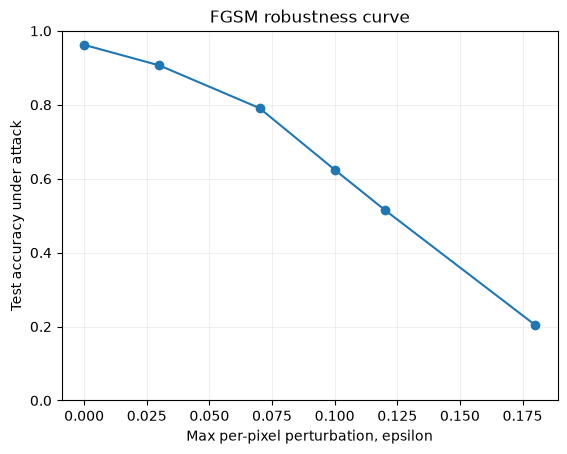

In [3]:
# STUDENT EXTENSION: own extra epsilon = 0.10 (fills the largest gap in the supplied grid, 0.07 -> 0.12)
import csv, os
os.makedirs('results', exist_ok=True)
epsilons = [0.00, 0.03, 0.07, 0.10, 0.12, 0.18]
clean_acc = accuracy_score(y_test, model.predict(X_test))
results = []
for eps in epsilons:
    changed = fgsm(model, X_test, y_test, epsilon=eps)
    acc = accuracy_score(y_test, model.predict(changed))
    results.append((eps, acc))
    print(f'Epsilon={eps:0.2f} | Accuracy={acc:.3f} | Drop={100*(clean_acc-acc):5.1f} percentage points')
with open('results/E03_fgsm_results.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['epsilon', 'accuracy', 'drop_percentage_points'])
    for eps, acc in results: w.writerow([eps, round(acc, 4), round(100*(clean_acc-acc), 1)])
plt.plot([p[0] for p in results], [p[1] for p in results], marker='o')
plt.xlabel('Max per-pixel perturbation, epsilon')
plt.ylabel('Test accuracy under attack')
plt.title('FGSM robustness curve')
plt.ylim(0, 1); plt.grid(alpha=.2)
plt.savefig('results/E03_fgsm_robustness_curve.png', dpi=200, bbox_inches='tight'); plt.show()

### Part B - Display clean and adversarial samples

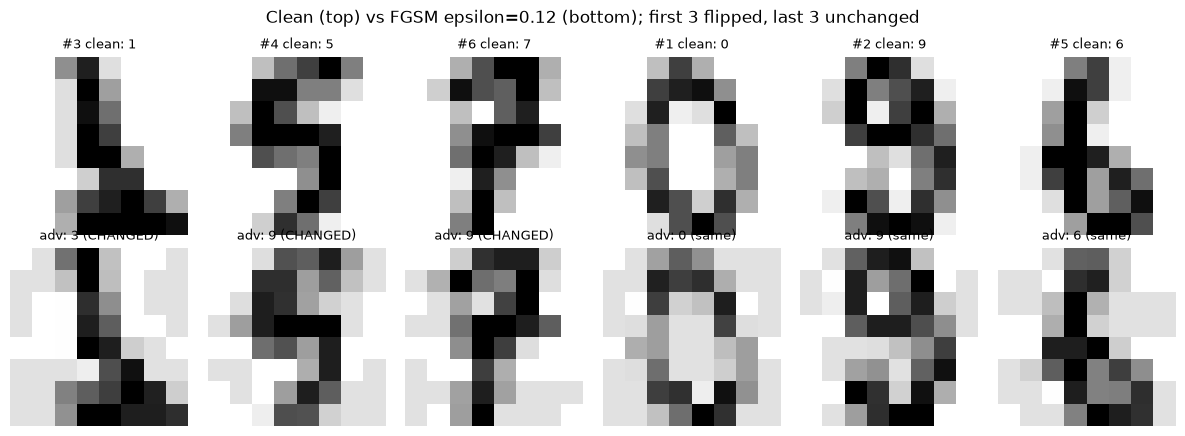

test idx 3: true 1 | clean pred 1 -> adversarial pred 3
test idx 4: true 5 | clean pred 5 -> adversarial pred 9
test idx 6: true 7 | clean pred 7 -> adversarial pred 9
test idx 1: true 0 | clean pred 0 -> adversarial pred 0
test idx 2: true 9 | clean pred 9 -> adversarial pred 9
test idx 5: true 6 | clean pred 6 -> adversarial pred 6
Max observed L-infinity change: 0.12


In [4]:
# STUDENT EXTENSION: choose pairs deliberately (clean-correct images only): 3 flipped, 3 unchanged
epsilon = 0.12
adversarial = fgsm(model, X_test, y_test, epsilon=epsilon)
clean_pred = model.predict(X_test); adv_pred = model.predict(adversarial)
ok = np.where(clean_pred == y_test)[0]
flipped = [i for i in ok if adv_pred[i] != clean_pred[i]][:3]
held = [i for i in ok if adv_pred[i] == clean_pred[i]][:3]
chosen = flipped + held
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for j, idx in enumerate(chosen):
    axes[0, j].imshow(X_test[idx].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[1, j].imshow(adversarial[idx].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[0, j].set_title(f'#{idx} clean: {clean_pred[idx]}', fontsize=9)
    axes[1, j].set_title(f'adv: {adv_pred[idx]}' + (' (CHANGED)' if adv_pred[idx] != clean_pred[idx] else ' (same)'), fontsize=9)
for ax in axes.ravel(): ax.axis('off')
plt.suptitle(f'Clean (top) vs FGSM epsilon={epsilon} (bottom); first 3 flipped, last 3 unchanged')
plt.tight_layout(); plt.savefig('results/E04_fgsm_image_pairs.png', dpi=200, bbox_inches='tight'); plt.show()
for idx in chosen:
    print(f'test idx {idx}: true {y_test[idx]} | clean pred {clean_pred[idx]} -> adversarial pred {adv_pred[idx]}')
print('Max observed L-infinity change:', np.max(np.abs(adversarial-X_test)))

In [5]:
# ADDED CELL: verify the epsilon bound and measure the effect of clipping and zero gradients
print('eps | max |change| | bound holds | mean |change| | pixels changed by < eps | pixels unchanged')
for eps in [0.03, 0.07, 0.10, 0.12, 0.18]:
    adv = fgsm(model, X_test, y_test, epsilon=eps)
    delta = np.abs(adv - X_test)
    grad = input_loss_gradient(model, X_test, y_test)
    unchanged = (delta < 1e-12).mean()
    smaller = ((delta > 1e-12) & (delta < eps - 1e-9)).mean()
    print(f'{eps:.2f} | {delta.max():.6f} | {delta.max() <= eps + 1e-12} | {delta.mean():.4f} | {100*smaller:5.1f}% | {100*unchanged:5.1f}%')
grad = input_loss_gradient(model, X_test, y_test)
print('Pixels with exactly zero gradient (sign=0, so no change):', f'{100*(grad == 0).mean():.1f}%')
print('Test pixels already at 0.0:', f'{100*(X_test == 0).mean():.1f}%', '| at 1.0:', f'{100*(X_test == 1).mean():.1f}%')

eps | max |change| | bound holds | mean |change| | pixels changed by < eps | pixels unchanged
0.03 | 0.030000 | True | 0.0221 |   0.0% |  26.2%
0.07 | 0.070000 | True | 0.0515 |   2.8% |  26.2%
0.10 | 0.100000 | True | 0.0728 |   2.8% |  26.2%
0.12 | 0.120000 | True | 0.0869 |   2.8% |  26.2%
0.18 | 0.180000 | True | 0.1280 |   5.5% |  26.2%
Pixels with exactly zero gradient (sign=0, so no change): 4.7%
Test pixels already at 0.0: 49.1% | at 1.0: 9.2%


### Student exercises
1. Repeat the experiment using an additional epsilon of your choice between 0.01 and 0.20.
2. Report the clean accuracy, attacked accuracy, maximum perturbation, and an example prediction change.
3. Identify the limits of the experiment, including image size, model type and threat assumptions.

**Deliverables:** robustness curve, selected images, result table and a short analysis. Do not use these methods against third-party systems.